In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import pickle
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, Ellipse
from sklearn.mixture import GaussianMixture

In [24]:
mgmm_20_in = "../syn_data/INLA_GMM/num_feat_20/val/epoch0/sub_dims.pickle"

In [26]:
with open(mgmm_20_in, "rb") as f:
    data = pickle.load(f)


In [68]:
root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load stored datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))
# find dataset with 2-dimensions
ix_2d = 0
data_2d = []
for i, data in enumerate(sub_dims_list):
    if len(data) == 2:
        ix_2d = i
        data_2d = data
        break

In [69]:
in_2d = in_list[ix_2d]
print((len(in_2d)))

5000


In [7]:
root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load stored datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find first dataset that has exactly 2 informative dims
# -------------------------------------------------
dataset_idx = []
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx.append(i)

In [8]:
print(dataset_idx)

[50, 51, 52, 55, 56, 57, 58, 60, 61, 64, 66, 68, 71, 74, 76, 82, 95, 118, 120, 123, 127, 129, 130, 140, 143, 147, 153, 155, 170, 176, 177, 180, 206, 207, 208, 209, 212, 215, 219, 225, 234, 236, 265, 268, 270, 271, 279, 284, 299, 302, 309, 320, 359, 374, 377, 383, 384, 399, 403, 407, 411, 415, 420, 421, 424, 439, 453, 455, 558, 562, 563, 566, 577, 607, 611, 620, 624, 669, 679, 686, 687, 701, 703, 734, 736, 771, 777, 778, 783, 789, 790, 798, 831, 832, 854, 857, 860, 870, 872, 873, 874, 877, 915, 917, 921, 935, 947, 948, 957, 971, 1006, 1013, 1016, 1048, 1049, 1054, 1055, 1059, 1081, 1084, 1087, 1090, 1095, 1102, 1103, 1104, 1117, 1120, 1124, 1127, 1130, 1146, 1149, 1150, 1161, 1166, 1173, 1187, 1190, 1198, 1200, 1202, 1203, 1210, 1211, 1230, 1265, 1270, 1271, 1275, 1337, 1351, 1352, 1361, 1364, 1378, 1381, 1400, 1404, 1409, 1424, 1425, 1427, 1431, 1470, 1482, 1484, 1486, 1492, 1509, 1518, 1531, 1532, 1533, 1535, 1536, 1538, 1540, 1550, 1557, 1573, 1587, 1590, 1591, 1600, 1609, 1612, 1613

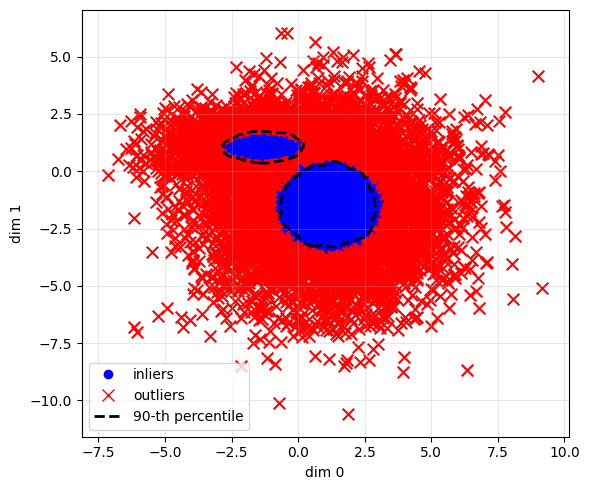

In [27]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from sklearn.mixture import GaussianMixture

root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load stored datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find datasets that have exactly 2 informative dims
# -------------------------------------------------
dataset_idx = []
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx.append(i)

if len(dataset_idx) == 0:
    raise ValueError("No dataset found with sub_dims = 2")

# choose one dataset
chosen_idx = dataset_idx[10]

# -------------------------------------------------
# Extract data
# -------------------------------------------------
inliers = np.asarray(in_list[chosen_idx])
outliers = np.asarray(la_list[chosen_idx])
sub_dims = list(sub_dims_list[chosen_idx])

# Use only informative dimensions
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# -------------------------------------------------
# Split inliers into 2 clusters
# -------------------------------------------------
gmm = GaussianMixture(n_components=2, random_state=0)
cluster_labels = gmm.fit_predict(in_2d)

# -------------------------------------------------
# Global grid for plotting
# -------------------------------------------------
xmin = min(in_2d[:, 0].min(), out_2d[:, 0].min()) - 1
xmax = max(in_2d[:, 0].max(), out_2d[:, 0].max()) + 1
ymin = min(in_2d[:, 1].min(), out_2d[:, 1].min()) - 1
ymax = max(in_2d[:, 1].max(), out_2d[:, 1].max()) + 1

nx, ny = 300, 300
xx, yy = np.meshgrid(
    np.linspace(xmin, xmax, nx),
    np.linspace(ymin, ymax, ny)
)
grid = np.c_[xx.ravel(), yy.ravel()]

# -------------------------------------------------
# Plot
# -------------------------------------------------
plt.figure(figsize=(6, 5))

# scatter
plt.scatter(in_2d[:, 0], in_2d[:, 1], c="blue", s=40)
plt.scatter(out_2d[:, 0], out_2d[:, 1], c="red", marker="x", s=70)

# -------------------------------------------------
# Draw one 90% contour per inlier cluster
# -------------------------------------------------
for k in range(2):
    cluster_points = in_2d[cluster_labels == k]

    # skip tiny clusters
    if len(cluster_points) < 5:
        continue

    # KDE for this cluster only
    kde_k = gaussian_kde(cluster_points.T)

    zz_k = kde_k(grid.T).reshape(xx.shape)

    # 90% highest-density region threshold
    dx = (xmax - xmin) / (nx - 1)
    dy = (ymax - ymin) / (ny - 1)
    cell_area = dx * dy

    z_flat = zz_k.ravel()
    order = np.argsort(z_flat)[::-1]
    z_sorted = z_flat[order]
    mass_sorted = z_sorted * cell_area
    cum_mass = np.cumsum(mass_sorted)

    target_mass = 0.90
    cut_idx = np.searchsorted(cum_mass, target_mass)
    cut_idx = min(cut_idx, len(z_sorted) - 1)
    thr_90 = z_sorted[cut_idx]

    # draw one contour for this cluster
    plt.contour(
        xx, yy, zz_k,
        levels=[thr_90],
        colors="black",
        linestyles="--",
        linewidths=2
    )

# legend
handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='inliers'),
    Line2D([0], [0], marker='x', color='red', linestyle='None', markersize=8, label='outliers'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='90-th percentile')
]

plt.legend(handles=handles)
plt.xlabel(f"dim {sub_dims[0]}")
plt.ylabel(f"dim {sub_dims[1]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig("MGMM_prior_full_dataset.png")
plt.show()

### MGMM - datasets with 50 samples

### random 20 points

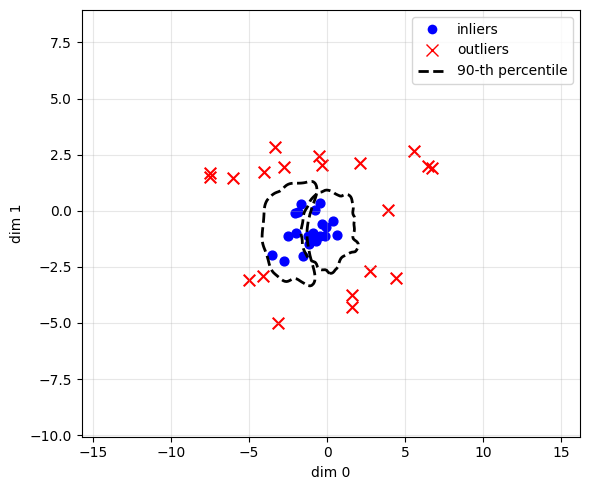

In [32]:
# Random 20 points - 2 clusters - MGMM
root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load stored datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find datasets that have exactly 2 informative dims
# -------------------------------------------------
dataset_idx = []
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx.append(i)

if len(dataset_idx) == 0:
    raise ValueError("No dataset found with sub_dims = 2")

# choose one dataset
chosen_idx = dataset_idx[40]

# -------------------------------------------------
# Extract data
# -------------------------------------------------
inliers = np.asarray(in_list[chosen_idx])
outliers = np.asarray(la_list[chosen_idx])
sub_dims = list(sub_dims_list[chosen_idx])

# Use only informative dimensions
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# Randomly draw 20 points for visualization
np.random.seed(0)
n_plot = 20

idx_in = np.random.choice(len(in_2d), n_plot, replace=False)
idx_out = np.random.choice(len(out_2d), n_plot, replace=False)

plot_in_2d = in_2d[idx_in]
plot_out_2d = out_2d[idx_out]

# -------------------------------------------------
# Split inliers into 2 clusters
# -------------------------------------------------
gmm = GaussianMixture(n_components=2, random_state=0)
cluster_labels = gmm.fit_predict(in_2d)

# -------------------------------------------------
# Global grid for plotting
# -------------------------------------------------
xmin = min(in_2d[:, 0].min(), out_2d[:, 0].min()) - 1
xmax = max(in_2d[:, 0].max(), out_2d[:, 0].max()) + 1
ymin = min(in_2d[:, 1].min(), out_2d[:, 1].min()) - 1
ymax = max(in_2d[:, 1].max(), out_2d[:, 1].max()) + 1

nx, ny = 300, 300
xx, yy = np.meshgrid(
    np.linspace(xmin, xmax, nx),
    np.linspace(ymin, ymax, ny)
)
grid = np.c_[xx.ravel(), yy.ravel()]

# -------------------------------------------------
# Plot
# -------------------------------------------------
plt.figure(figsize=(6, 5))

# scatter
plt.scatter(plot_in_2d[:, 0], plot_in_2d[:, 1], c="blue", s=40)
plt.scatter(plot_out_2d[:, 0], plot_out_2d[:, 1], c="red", marker="x", s=70)

# -------------------------------------------------
# Draw one 90% contour per inlier cluster
# -------------------------------------------------
for k in range(2):
    cluster_points = in_2d[cluster_labels == k]

    # skip tiny clusters
    if len(cluster_points) < 5:
        continue

    # KDE for this cluster only
    kde_k = gaussian_kde(cluster_points.T)

    zz_k = kde_k(grid.T).reshape(xx.shape)

    # 90% highest-density region threshold
    dx = (xmax - xmin) / (nx - 1)
    dy = (ymax - ymin) / (ny - 1)
    cell_area = dx * dy

    z_flat = zz_k.ravel()
    order = np.argsort(z_flat)[::-1]
    z_sorted = z_flat[order]
    mass_sorted = z_sorted * cell_area
    cum_mass = np.cumsum(mass_sorted)

    target_mass = 0.90
    cut_idx = np.searchsorted(cum_mass, target_mass)
    cut_idx = min(cut_idx, len(z_sorted) - 1)
    thr_90 = z_sorted[cut_idx]

    # draw one contour for this cluster
    plt.contour(
        xx, yy, zz_k,
        levels=[thr_90],
        colors="black",
        linestyles="--",
        linewidths=2
    )

# legend
handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='inliers'),
    Line2D([0], [0], marker='x', color='red', linestyle='None', markersize=8, label='outliers'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='90-th percentile')
]

plt.legend(handles=handles)
plt.xlabel(f"dim {sub_dims[0]}")
plt.ylabel(f"dim {sub_dims[1]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig("MGMM_prior_full_dataset.png")
plt.show()

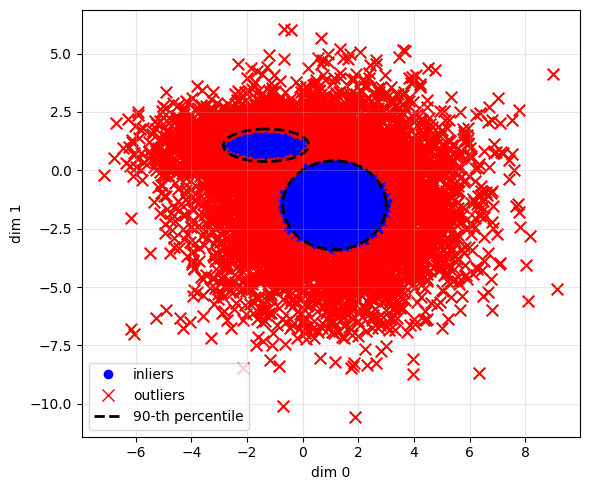

In [54]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture

root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def draw_gmm_ellipse(mean, cov, ax, percentile=0.90, **kwargs):
    """
    Draw a 2D Gaussian confidence ellipse.
    For 2D:
      80% -> chi2 = 3.219
      90% -> chi2 = 4.605
      95% -> chi2 = 5.991
      99% -> chi2 = 9.210
    """
    chi2_map = {
        0.80: 3.219,
        0.90: 5.0, #4.605,
        0.95: 5.991,
        0.99: 9.210
    }

    if percentile not in chi2_map:
        raise ValueError("Supported percentiles: 0.80, 0.90, 0.95, 0.99")

    scale = np.sqrt(chi2_map[percentile])

    # Eigen-decomposition of covariance
    vals, vecs = np.linalg.eigh(cov)

    # Sort eigenvalues descending
    order = vals.argsort()[::-1]
    vals = vals[order]
    vecs = vecs[:, order]

    # Angle of major axis
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    # Ellipse width/height
    width = 2 * scale * np.sqrt(vals[0])
    height = 2 * scale * np.sqrt(vals[1])

    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        **kwargs
    )
    ax.add_patch(ellipse)

# -------------------------------------------------
# Load stored datasets
# -------------------------------------------------
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find datasets with exactly 2 informative dims
# -------------------------------------------------
dataset_idx = []
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx.append(i)

if len(dataset_idx) == 0:
    raise ValueError("No dataset found with sub_dims = 2")

# choose one dataset
chosen_idx = dataset_idx[10]

# -------------------------------------------------
# Extract data
# -------------------------------------------------
inliers = np.asarray(in_list[chosen_idx])
outliers = np.asarray(la_list[chosen_idx])
sub_dims = list(sub_dims_list[chosen_idx])

# Use only informative dimensions
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# -------------------------------------------------
# Fit 2-component GMM to inliers
# -------------------------------------------------
n_clusters = 2
gmm = GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=0)
gmm.fit(in_2d)

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(in_2d[:, 0], in_2d[:, 1], c="blue", s=40)
ax.scatter(out_2d[:, 0], out_2d[:, 1], c="red", marker="x", s=70)

# Draw one ellipse per cluster
for k in range(n_clusters):
    mean = gmm.means_[k]
    cov = gmm.covariances_[k]

    draw_gmm_ellipse(
        mean,
        cov,
        ax,
        percentile=0.90,   # change to 0.80, 0.95, etc. if needed
        edgecolor="black",
        linestyle="--",
        linewidth=2
    )

handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='inliers'),
    Line2D([0], [0], marker='x', color='red', linestyle='None', markersize=8, label='outliers'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='90-th percentile')
]

ax.legend(handles=handles)
ax.set_xlabel(f"dim {sub_dims[0]}")
ax.set_ylabel(f"dim {sub_dims[1]}")
ax.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig("MGMM_prior_2_clusters_dataset.png")
plt.show()

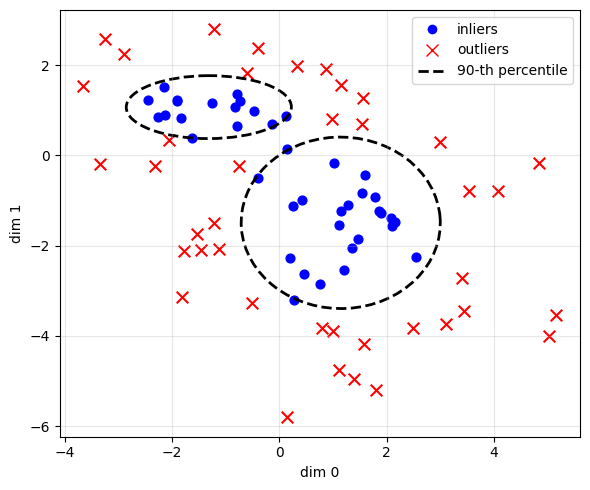

In [60]:

root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def draw_gmm_ellipse(mean, cov, ax, percentile=0.90, **kwargs):
    """
    Draw a 2D Gaussian confidence ellipse.
    For 2D:
      80% -> chi2 = 3.219
      90% -> chi2 = 4.605
      95% -> chi2 = 5.991
      99% -> chi2 = 9.210
    """
    chi2_map = {
        0.80: 3.219,
        0.90: 5.0, #4.605,
        0.95: 5.991,
        0.99: 9.210
    }

    if percentile not in chi2_map:
        raise ValueError("Supported percentiles: 0.80, 0.90, 0.95, 0.99")

    scale = np.sqrt(chi2_map[percentile])

    # Eigen-decomposition of covariance
    vals, vecs = np.linalg.eigh(cov)

    # Sort eigenvalues descending
    order = vals.argsort()[::-1]
    vals = vals[order]
    vecs = vecs[:, order]

    # Angle of major axis
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    # Ellipse width/height
    width = 2 * scale * np.sqrt(vals[0])
    height = 2 * scale * np.sqrt(vals[1])

    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        **kwargs
    )
    ax.add_patch(ellipse)

# -------------------------------------------------
# Load stored datasets
# -------------------------------------------------
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find datasets with exactly 2 informative dims
# -------------------------------------------------
dataset_idx = []
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx.append(i)

if len(dataset_idx) == 0:
    raise ValueError("No dataset found with sub_dims = 2")

# choose one dataset
chosen_idx = dataset_idx[10]

# -------------------------------------------------
# Extract data
# -------------------------------------------------
inliers = np.asarray(in_list[chosen_idx])
outliers = np.asarray(la_list[chosen_idx])
sub_dims = list(sub_dims_list[chosen_idx])

# Use only informative dimensions
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# Randomly draw 20 points for visualization
np.random.seed(0)
n_plot = 40

idx_in = np.random.choice(len(in_2d), n_plot, replace=False)
idx_out = np.random.choice(len(out_2d), n_plot, replace=False)

plot_in_2d = in_2d[idx_in]
plot_out_2d = out_2d[idx_out]

# -------------------------------------------------
# Fit 2-component GMM to inliers
# -------------------------------------------------
n_clusters = 2
gmm = GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=0)
gmm.fit(in_2d)

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(plot_in_2d[:, 0], plot_in_2d[:, 1], c="blue", s=40)
ax.scatter(plot_out_2d[:, 0], plot_out_2d[:, 1], c="red", marker="x", s=70)

# Draw one ellipse per cluster
for k in range(n_clusters):
    mean = gmm.means_[k]
    cov = gmm.covariances_[k]

    draw_gmm_ellipse(
        mean,
        cov,
        ax,
        percentile=0.90,   # change to 0.80, 0.95, etc. if needed
        edgecolor="black",
        linestyle="--",
        linewidth=2
    )

handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='inliers'),
    Line2D([0], [0], marker='x', color='red', linestyle='None', markersize=8, label='outliers'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='90-th percentile')
]

ax.legend(handles=handles)
ax.set_xlabel(f"dim {sub_dims[0]}")
ax.set_ylabel(f"dim {sub_dims[1]}")
ax.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig("MGMM_prior_2_clusters_50_random_points.png")
plt.show()

## 1. Draw MGMM 

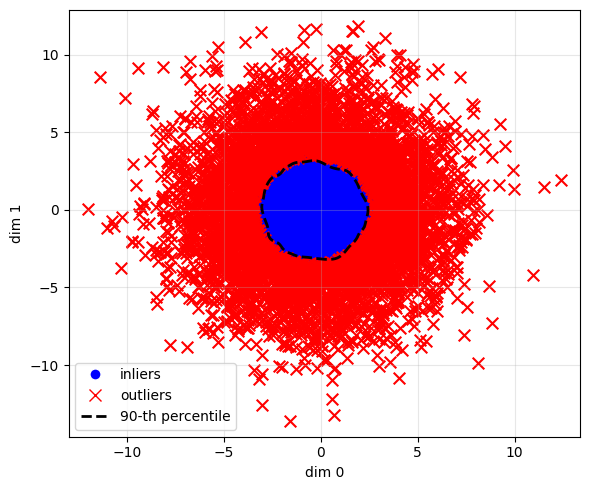

In [ ]:
root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load stored datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find first dataset that has exactly 2 informative dims
# -------------------------------------------------
dataset_idx = None
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx = i
        break

# -------------------------------------------------
# Extract data
# -------------------------------------------------
inliers = np.array(in_list[dataset_idx])
outliers = np.array(la_list[dataset_idx])
sub_dims = sub_dims_list[dataset_idx]

# Use only informative dimensions
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# -------------------------------------------------
# Fit density ONLY on inliers
# -------------------------------------------------
kde = gaussian_kde(in_2d.T)

# Grid for contour
xmin = min(in_2d[:,0].min(), out_2d[:,0].min()) - 1
xmax = max(in_2d[:,0].max(), out_2d[:,0].max()) + 1
ymin = min(in_2d[:,1].min(), out_2d[:,1].min()) - 1
ymax = max(in_2d[:,1].max(), out_2d[:,1].max()) + 1

xx, yy = np.meshgrid(
    np.linspace(xmin, xmax, 300),
    np.linspace(ymin, ymax, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
zz = kde(grid.T).reshape(xx.shape)

# -------------------------------------------------
# 90% inlier boundary
# -------------------------------------------------
inlier_density = kde(in_2d.T)
thr_90 = np.percentile(inlier_density, 2)

# -------------------------------------------------
# Plot
# -------------------------------------------------
plt.figure(figsize=(6,5))

# scatter
plt.scatter(in_2d[:,0], in_2d[:,1], c="blue", s=40)
plt.scatter(out_2d[:,0], out_2d[:,1], c="red", marker="x", s=70)

# density contours
#plt.contour(xx, yy, zz, levels=10, colors="purple", linewidths=0.8)

# dashed boundary around inliers
plt.contour(xx, yy, zz, levels=[thr_90], colors="black", linestyles="--", linewidths=2)

# legend
handles = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor='blue',markersize=8,label='inliers'),
    Line2D([0],[0],marker='x',color='red',linestyle='None',markersize=8,label='outliers'),
    Line2D([0],[0],color='black',linestyle='--',linewidth=2,label='90-th percentile')
]

plt.legend(handles=handles)

plt.xlabel(f"dim {sub_dims[0]}")
plt.ylabel(f"dim {sub_dims[1]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
#plt.savefig("MGMM_prior_full_dataset.png")
plt.show()

### MGMM - 20 points

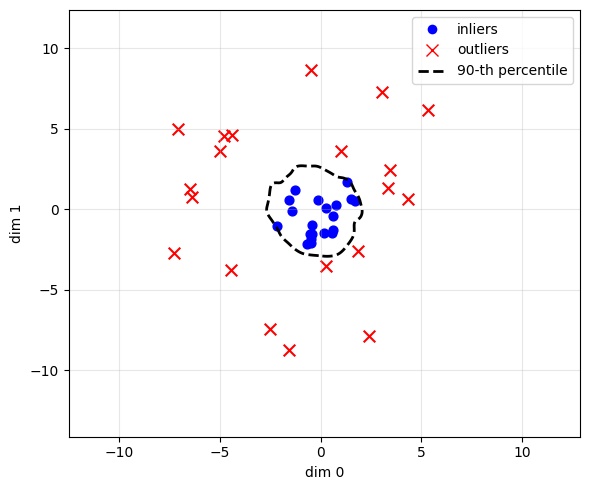

In [ ]:

root = "../syn_data/INLA_GMM/num_feat_10_MGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# -------------------------------------------------
# Load stored datasets
# -------------------------------------------------
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# -------------------------------------------------
# Find dataset with sub_dims == 2
# -------------------------------------------------
dataset_idx = None
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx = i
        break

# Extract dataset
inliers = np.asarray(in_list[dataset_idx])
outliers = np.asarray(la_list[dataset_idx])
sub_dims = list(sub_dims_list[dataset_idx])

# Use only informative dimensions
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# Randomly draw 20 points for visualization
np.random.seed(0)
n_plot = 20

idx_in = np.random.choice(len(in_2d), n_plot, replace=False)
idx_out = np.random.choice(len(out_2d), n_plot, replace=False)

plot_in_2d = in_2d[idx_in]
plot_out_2d = out_2d[idx_out]


# Fit KDE on ALL inliers
kde = gaussian_kde(in_2d.T)

# -------------------------------------------------
# Grid for density evaluation
# -------------------------------------------------
pad = 0.5

xmin = min(in_2d[:,0].min(), out_2d[:,0].min()) - pad
xmax = max(in_2d[:,0].max(), out_2d[:,0].max()) + pad
ymin = min(in_2d[:,1].min(), out_2d[:,1].min()) - pad
ymax = max(in_2d[:,1].max(), out_2d[:,1].max()) + pad

nx, ny = 400, 400

xx, yy = np.meshgrid(
    np.linspace(xmin, xmax, nx),
    np.linspace(ymin, ymax, ny)
)

grid = np.c_[xx.ravel(), yy.ravel()]
zz = kde(grid.T).reshape(xx.shape)

# Correct 80% highest density region (HDR)
dx = (xmax - xmin) / (nx - 1)
dy = (ymax - ymin) / (ny - 1)
cell_area = dx * dy

z_flat = zz.ravel()
order = np.argsort(z_flat)[::-1]

z_sorted = z_flat[order]
mass = z_sorted * cell_area
cum_mass = np.cumsum(mass)

target_mass = 0.90
cut_idx = np.searchsorted(cum_mass, target_mass)
cut_idx = min(cut_idx, len(z_sorted)-1)

thr_80 = z_sorted[cut_idx]

# -------------------------------------------------
# Plot
# -------------------------------------------------
plt.figure(figsize=(6,5))

plt.scatter(plot_in_2d[:,0], plot_in_2d[:,1], c="blue", s=40)
plt.scatter(plot_out_2d[:,0], plot_out_2d[:,1], c="red", marker="x", s=70)

# 90% boundary
plt.contour(xx, yy, zz,
            levels=[thr_80],
            colors="black",
            linestyles="--",
            linewidths=2)

handles = [
    Line2D([0],[0],marker='o',color='w',markerfacecolor='blue',markersize=8,label='inliers'),
    Line2D([0],[0],marker='x',color='red',linestyle='None',markersize=8,label='outliers'),
    Line2D([0],[0],color='black',linestyle='--',linewidth=2,label='90-th percentile')
]

plt.legend(handles=handles)

plt.xlabel(f"dim {sub_dims[0]}")
plt.ylabel(f"dim {sub_dims[1]}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
#plt.savefig("MGMM_prior_20_random_points.png")
plt.show()

## 2. SGMM

Using dataset: 4


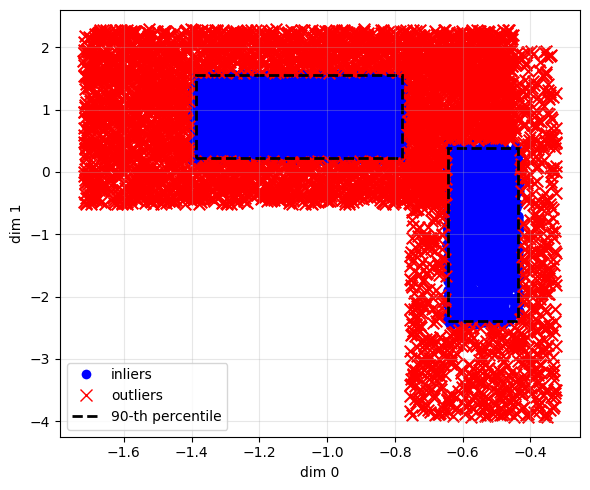

In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from sklearn.mixture import GaussianMixture

root = "../syn_data/INLA_GMM/num_feat_10_SGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# Find first dataset with exactly 2 informative dims
dataset_idx = None
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx = i
        break

if dataset_idx is None:
    raise ValueError("No dataset found with sub_dims = 2")

print("Using dataset:", dataset_idx)

# Extract data
inliers = np.asarray(in_list[dataset_idx])
outliers = np.asarray(la_list[dataset_idx])
sub_dims = list(sub_dims_list[dataset_idx])

# Keep only informative dims
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]


plot_in_2d = in_2d
plot_out_2d = out_2d

# -------------------------------------------------
# Fit GMM to split inliers into clusters
# -------------------------------------------------
n_clusters = 2   # change this if needed
gmm = GaussianMixture(n_components=n_clusters, random_state=0)
labels = gmm.fit_predict(in_2d)

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(plot_in_2d[:, 0], plot_in_2d[:, 1], c="blue", s=40)
ax.scatter(plot_out_2d[:, 0], plot_out_2d[:, 1], c="red", marker="x", s=70)

# Draw one dashed rectangle per cluster
for k in range(n_clusters):
    cluster_points = in_2d[labels == k]

    if len(cluster_points) < 5:
        continue

    # central 80% rectangle for this cluster
    x_low, x_high = np.percentile(cluster_points[:, 0], [2, 98])
    y_low, y_high = np.percentile(cluster_points[:, 1], [2, 98])

    rect = Rectangle(
        (x_low, y_low),
        x_high - x_low,
        y_high - y_low,
        fill=False,
        edgecolor="black",
        linestyle="--",
        linewidth=2
    )
    ax.add_patch(rect)

handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='inliers'),
    Line2D([0], [0], marker='x', color='red', linestyle='None', markersize=8, label='outliers'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='90-th percentile')
]

ax.legend(handles=handles)
ax.set_xlabel(f"dim {sub_dims[0]}")
ax.set_ylabel(f"dim {sub_dims[1]}")
ax.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig("SGMM_prior_full_dataset.png")
plt.show()

### SGMM - for 20 random points

Using dataset: 4


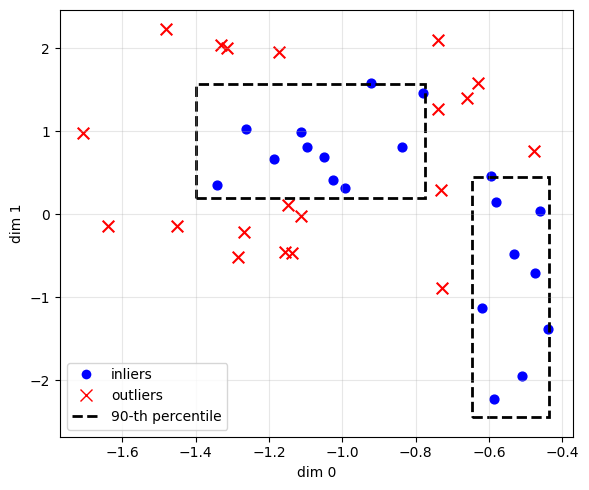

In [11]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from sklearn.mixture import GaussianMixture

root = "../syn_data/INLA_GMM/num_feat_10_SGMM/val/epoch0"

def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

# Load datasets
in_list = load_pickle(os.path.join(root, "in.pickle"))
la_list = load_pickle(os.path.join(root, "la.pickle"))
sub_dims_list = load_pickle(os.path.join(root, "sub_dims.pickle"))

# Find first dataset with exactly 2 informative dims
dataset_idx = None
for i, sd in enumerate(sub_dims_list):
    if sd is not None and len(sd) == 2:
        dataset_idx = i
        break

if dataset_idx is None:
    raise ValueError("No dataset found with sub_dims = 2")

print("Using dataset:", dataset_idx)

# Extract data
inliers = np.asarray(in_list[dataset_idx])
outliers = np.asarray(la_list[dataset_idx])
sub_dims = list(sub_dims_list[dataset_idx])

# Keep only informative dims
in_2d = inliers[:, sub_dims]
out_2d = outliers[:, sub_dims]

# Random 20 points for display
np.random.seed(0)
n_plot = 20
idx_in = np.random.choice(len(in_2d), min(n_plot, len(in_2d)), replace=False)
idx_out = np.random.choice(len(out_2d), min(n_plot, len(out_2d)), replace=False)

plot_in_2d = in_2d[idx_in]
plot_out_2d = out_2d[idx_out]

# -------------------------------------------------
# Fit GMM to split inliers into clusters
# -------------------------------------------------
n_clusters = 2   # change this if needed
gmm = GaussianMixture(n_components=n_clusters, random_state=0)
labels = gmm.fit_predict(in_2d)

# -------------------------------------------------
# Plot
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(plot_in_2d[:, 0], plot_in_2d[:, 1], c="blue", s=40)
ax.scatter(plot_out_2d[:, 0], plot_out_2d[:, 1], c="red", marker="x", s=70)

# Draw one dashed rectangle per cluster
for k in range(n_clusters):
    cluster_points = in_2d[labels == k]

    if len(cluster_points) < 5:
        continue

    # central 80% rectangle for this cluster
    x_low, x_high = np.percentile(cluster_points[:, 0], [0, 99])
    y_low, y_high = np.percentile(cluster_points[:, 1], [0, 99])

    rect = Rectangle(
        (x_low, y_low),
        x_high - x_low,
        y_high - y_low,
        fill=False,
        edgecolor="black",
        linestyle="--",
        linewidth=2
    )
    ax.add_patch(rect)

handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, label='inliers'),
    Line2D([0], [0], marker='x', color='red', linestyle='None', markersize=8, label='outliers'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='90-th percentile')
]

ax.legend(handles=handles)
ax.set_xlabel(f"dim {sub_dims[0]}")
ax.set_ylabel(f"dim {sub_dims[1]}")
ax.grid(True, alpha=0.3)

plt.tight_layout()
#plt.savefig('SGMM_prior_50_random_points.png')
plt.show()